# Handwritten Digit Recognition with a CNN (CodeAlpha ML Internship - Task 3)
Goal: recognize handwritten digits (0-9) from 28x28 grayscale images.
Dataset: MNIST (70,000 images). Model: Convolutional Neural Network (TensorFlow / Keras).
Run on Google Colab (Runtime > Change runtime type > GPU) or on a machine with TensorFlow installed.

In [2]:
import os, random, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
EPOCHS = 15
print("TensorFlow:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))

TensorFlow: 2.21.0
GPU available: False


## 1. Load data

In [3]:
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.mnist.load_data()
print("Train:", x_train_full.shape, "Test:", x_test.shape)
print("Pixel range:", x_train_full.min(), "-", x_train_full.max())

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
Train: (60000, 28, 28) Test: (10000, 28, 28)
Pixel range: 0 - 255


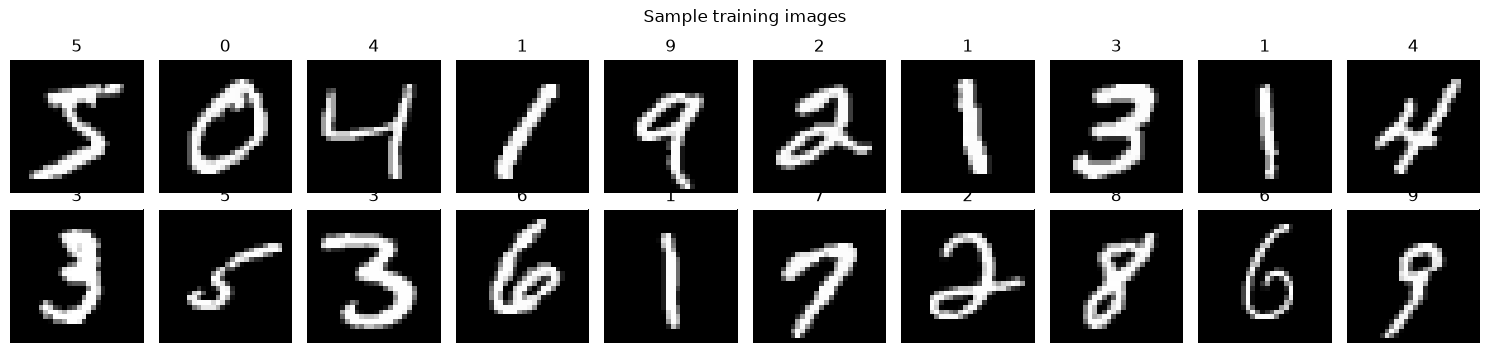

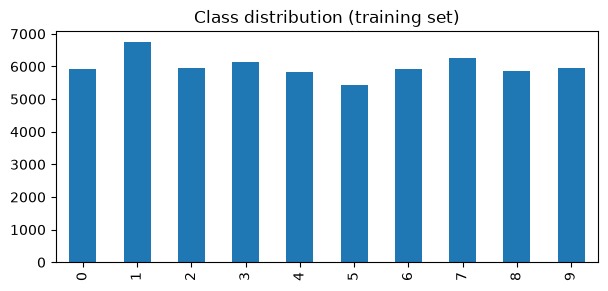

In [4]:
fig, axes = plt.subplots(2, 10, figsize=(15, 3.6))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(x_train_full[i], cmap="gray"); ax.set_title(int(y_train_full[i])); ax.axis("off")
plt.suptitle("Sample training images"); plt.tight_layout(); plt.show()

pd.Series(y_train_full).value_counts().sort_index().plot(
    kind="bar", figsize=(7, 3), title="Class distribution (training set)"); plt.show()

## 2. Preprocessing
Scale pixels to [0, 1], add a channel dimension, and hold out 10% of training data for validation.

In [5]:
def prep(x):
    return (x.astype("float32") / 255.0)[..., np.newaxis]

x_train_full, x_test = prep(x_train_full), prep(x_test)
n_val = 6000
idx = np.random.permutation(len(x_train_full))
x_val, y_val = x_train_full[idx[:n_val]], y_train_full[idx[:n_val]]
x_train, y_train = x_train_full[idx[n_val:]], y_train_full[idx[n_val:]]
print("train / val / test:", x_train.shape[0], x_val.shape[0], x_test.shape[0])

train / val / test: 54000 6000 10000


## 3. CNN model
Small random rotation, shift and zoom (data augmentation, active only during training)
help the model handle different handwriting styles.

In [6]:
def build_model():
    return keras.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.RandomRotation(0.06), layers.RandomTranslation(0.08, 0.08), layers.RandomZoom(0.08),
        layers.Conv2D(32, 3, padding="same", activation="relu"), layers.BatchNormalization(),
        layers.Conv2D(32, 3, padding="same", activation="relu"), layers.BatchNormalization(),
        layers.MaxPooling2D(), layers.Dropout(0.25),
        layers.Conv2D(64, 3, padding="same", activation="relu"), layers.BatchNormalization(),
        layers.Conv2D(64, 3, padding="same", activation="relu"), layers.BatchNormalization(),
        layers.MaxPooling2D(), layers.Dropout(0.25),
        layers.Flatten(),
        layers.Dense(128, activation="relu"), layers.Dropout(0.4),
        layers.Dense(10, activation="softmax"),
    ])

model = build_model()
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_rotation                 │ (None, 28, 28, 1)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 28, 28, 1)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 468,586 (1.79 MB)

 Trainable params: 468,202 (1.79 MB)

 Non-trainable params: 384 (1.50 KB)

## 4. Train
EarlyStopping and ReduceLROnPlateau stop the training when it no longer improves.

In [7]:
callbacks = [
    keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True, monitor="val_accuracy"),
    keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=2, min_lr=1e-5, monitor="val_loss"),
]
history = model.fit(x_train, y_train, validation_data=(x_val, y_val),
                    epochs=EPOCHS, batch_size=128, callbacks=callbacks, verbose=2)

Epoch 1/15
422/422 - 42s - 100ms/step - accuracy: 0.8530 - loss: 0.4673 - val_accuracy: 0.9237 - val_loss: 0.2495 - learning_rate: 0.0010
Epoch 2/15
422/422 - 39s - 91ms/step - accuracy: 0.9502 - loss: 0.1687 - val_accuracy: 0.9788 - val_loss: 0.0792 - learning_rate: 0.0010
Epoch 3/15
422/422 - 37s - 88ms/step - accuracy: 0.9624 - loss: 0.1289 - val_accuracy: 0.9882 - val_loss: 0.0478 - learning_rate: 0.0010
Epoch 4/15
422/422 - 38s - 90ms/step - accuracy: 0.9689 - loss: 0.1101 - val_accuracy: 0.9863 - val_loss: 0.0531 - learning_rate: 0.0010
Epoch 5/15
422/422 - 39s - 93ms/step - accuracy: 0.9724 - loss: 0.0980 - val_accuracy: 0.9865 - val_loss: 0.0560 - learning_rate: 0.0010
Epoch 6/15
422/422 - 37s - 88ms/step - accuracy: 0.9781 - loss: 0.0741 - val_accuracy: 0.9898 - val_loss: 0.0377 - learning_rate: 5.0000e-04
Epoch 7/15
422/422 - 38s - 90ms/step - accuracy: 0.9809 - loss: 0.0676 - val_accuracy: 0.9917 - val_loss: 0.0285 - learning_rate: 5.0000e-04
Epoch 8/15
422/422 - 38s - 89ms/

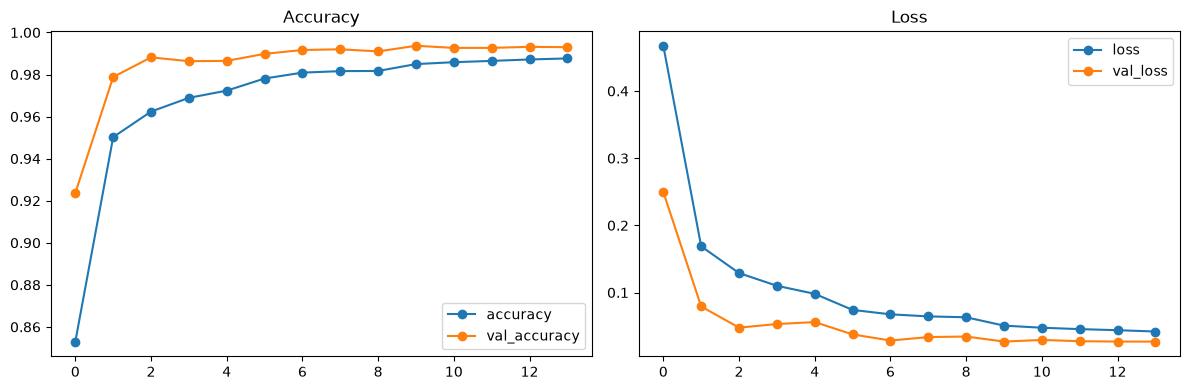

In [8]:
h = pd.DataFrame(history.history)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
h[["accuracy", "val_accuracy"]].plot(ax=ax[0], title="Accuracy", marker="o")
h[["loss", "val_loss"]].plot(ax=ax[1], title="Loss", marker="o")
plt.tight_layout(); plt.show()

## 5. Evaluation on the test set

In [9]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Test accuracy: {test_acc:.4f}   Test loss: {test_loss:.4f}")
proba = model.predict(x_test, verbose=0)
y_pred = proba.argmax(axis=1)
print(classification_report(y_test, y_pred, digits=4))

Test accuracy: 0.9938   Test loss: 0.0174
              precision    recall  f1-score   support

           0     0.9980    0.9969    0.9974       980
           1     0.9965    0.9921    0.9943      1135
           2     0.9971    0.9922    0.9947      1032
           3     0.9911    0.9970    0.9941      1010
           4     0.9909    0.9969    0.9939       982
           5     0.9966    0.9922    0.9944       892
           6     0.9948    0.9916    0.9932       958
           7     0.9827    0.9961    0.9894      1028
           8     0.9938    0.9949    0.9944       974
           9     0.9970    0.9881    0.9925      1009

    accuracy                         0.9938     10000
   macro avg     0.9938    0.9938    0.9938     10000
weighted avg     0.9938    0.9938    0.9938     10000



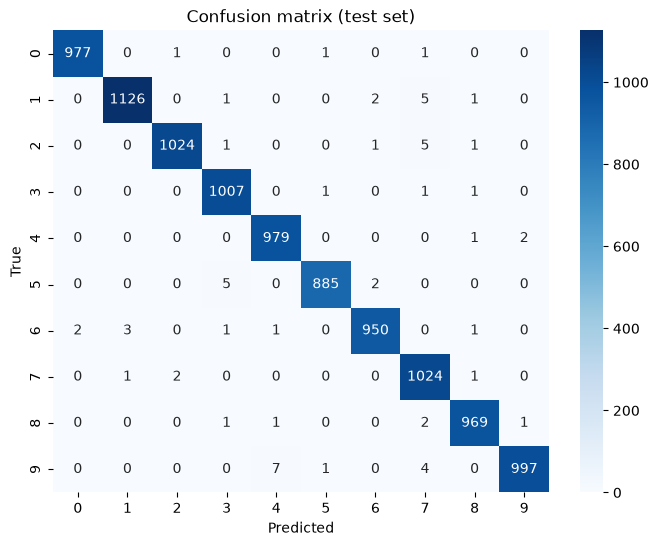

Most common mistakes (count, true -> predicted):
    7   9 -> 4
    5   5 -> 3
    5   2 -> 7
    5   1 -> 7
    4   9 -> 7


In [10]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion matrix (test set)"); plt.show()

off = cm.copy(); np.fill_diagonal(off, 0)
pairs = sorted([(off[i, j], i, j) for i in range(10) for j in range(10) if off[i, j] > 0], reverse=True)[:5]
print("Most common mistakes (count, true -> predicted):")
for n, t, p in pairs:
    print(f"  {n:3d}   {t} -> {p}")

## 6. Misclassified examples

62 of 10000 test images misclassified


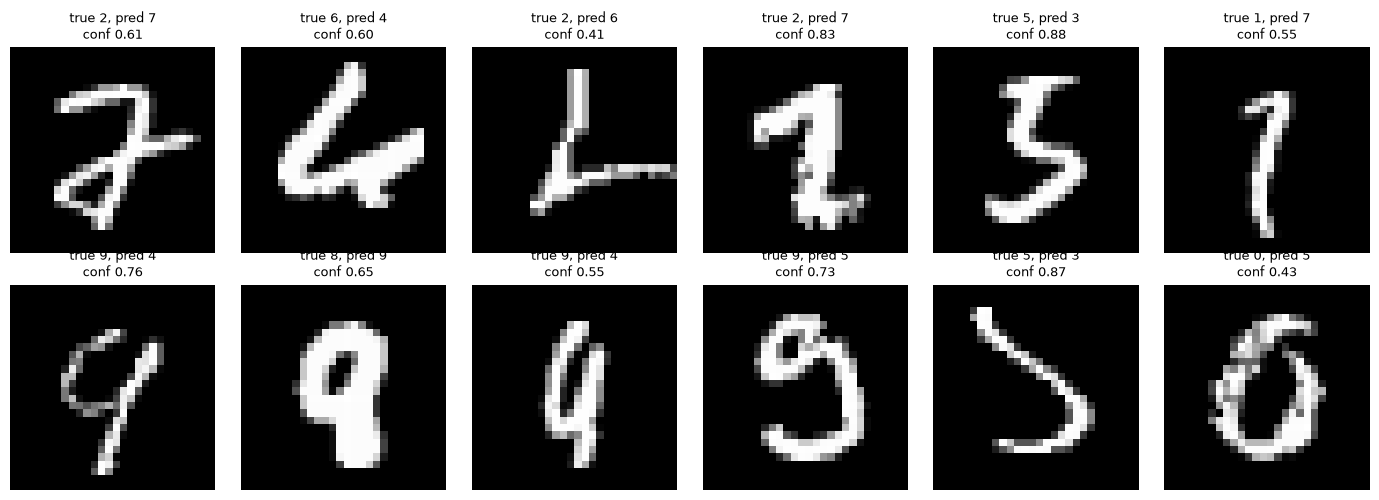

In [11]:
wrong = np.where(y_pred != y_test)[0]
print(f"{len(wrong)} of {len(y_test)} test images misclassified")
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for ax, i in zip(axes.ravel(), wrong[:12]):
    ax.imshow(x_test[i].squeeze(), cmap="gray")
    ax.set_title(f"true {y_test[i]}, pred {y_pred[i]}\nconf {proba[i].max():.2f}", fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()

## 7. Predict on your own handwriting
Write a digit in black on white paper (or white on black), take a photo or screenshot, upload it,
and call `predict_image("your_file.png")`. The function converts it to a 28x28 MNIST-style image.

In [12]:
from PIL import Image, ImageOps

def predict_image(path, show=True):
    img = Image.open(path).convert("L")
    if np.array(img).mean() > 127:          # white background -> invert to match MNIST
        img = ImageOps.invert(img)
    img = ImageOps.autocontrast(img)
    bbox = img.getbbox()                     # crop to the digit and pad to a square
    if bbox:
        img = img.crop(bbox)
    side = max(img.size)
    square = Image.new("L", (int(side * 1.4), int(side * 1.4)), 0)
    square.paste(img, ((square.size[0] - img.size[0]) // 2, (square.size[1] - img.size[1]) // 2))
    arr = np.array(square.resize((28, 28), Image.LANCZOS), dtype="float32") / 255.0
    p = model.predict(arr[np.newaxis, ..., np.newaxis], verbose=0)[0]
    if show:
        plt.imshow(arr, cmap="gray"); plt.axis("off")
        plt.title(f"Prediction: {p.argmax()} (confidence {p.max():.2f})"); plt.show()
    return int(p.argmax()), float(p.max())

# In Google Colab, upload a file first:
# from google.colab import files; uploaded = files.upload(); predict_image(list(uploaded)[0])

## 8. Save model

In [13]:
model.save("mnist_cnn_model.keras")
print("Saved mnist_cnn_model.keras")

Saved mnist_cnn_model.keras


## Conclusion
Write here: final test accuracy, which digits were confused most, and ideas for improvement.

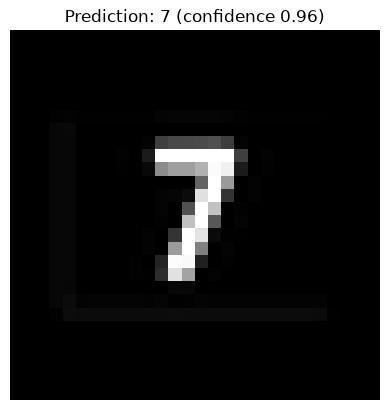

(7, 0.9562121033668518)

In [21]:
predict_image("c:/Users/RAVINDRA DAS/Downloads/seven.jpg.jpg")

A CNN with batch normalization, dropout and light data augmentation was trained on MNIST (54,000 training, 6,000 validation images). On the 10,000 unseen test images it reached 99.38% accuracy (test loss 0.0174), with 62 misclassified images. Precision, recall and F1 were above 0.98 for every digit.

The most common mistakes were 9 predicted as 4 (7 times), 5 as 3, 2 as 7 and 1 as 7 (5 times each), and 9 as 7 (4 times). These digits can look alike in handwriting. Digit 7 had the lowest precision (0.983) and digit 9 the lowest recall (0.988).

A bold computer-font image of a 7 was also tested and predicted correctly (confidence 0.96). The model is trained on clean, centered MNIST digits, so photos of real handwriting may need a plain background and a clearly drawn digit. Possible improvements: train on EMNIST to recognize letters, add more augmentation, or use a CRNN to recognize full words.